In [23]:
%pip install -r "/Users/sonamkumari/Churn Prediction/requirements.txt"

3050.76s - pydevd: Sending message related to process being replaced timed-out after 5 seconds


Note: you may need to restart the kernel to use updated packages.


In [18]:
import os
print("Kernel restarted")

Kernel restarted


In [ ]:
import pandas
import numpy
import sklearn
import streamlit
import joblib
import kagglehub

print("All imports OK")

All imports OK


In [27]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv("/Users/sonamkumari/Churn Prediction/data/churn.csv")
print(df.shape)
df.head()

(7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [28]:

import os, glob, shutil, kagglehub
path = kagglehub.dataset_download("palashfendarkar/wa-fnusec-telcocustomerchurn")
csv_files = glob.glob(os.path.join(path, "**", "*.csv"), recursive=True)
print(csv_files)
if not csv_files:
    raise FileNotFoundError("No CSV found in downloaded dataset")
src = csv_files[0]
dst = "/Users/sonamkumari/Churn Prediction/data/churn.csv"
shutil.copy(src, dst)
print("Copied to:", dst)


['/Users/sonamkumari/.cache/kagglehub/datasets/palashfendarkar/wa-fnusec-telcocustomerchurn/versions/1/WA_Fn-UseC_-Telco-Customer-Churn.csv']
Copied to: /Users/sonamkumari/Churn Prediction/data/churn.csv


In [29]:
target = df["Churn"]
if not pd.api.types.is_numeric_dtype(target):
    target = target.str.strip().str.lower().map({"yes": 1, "no": 0})

print("Churn rate:", round(target.mean(), 3))

print("Baseline accuracy (always guess the majority):", round(max(target.mean(), 1 - target.mean()), 3))

print("Duplicate rows:", df.duplicated().sum())

print("Missing values:\n", df.isnull().sum()[df.isnull().sum() > 0])

Churn rate: 0.265
Baseline accuracy (always guess the majority): 0.735
Duplicate rows: 0
Missing values:
 Series([], dtype: int64)


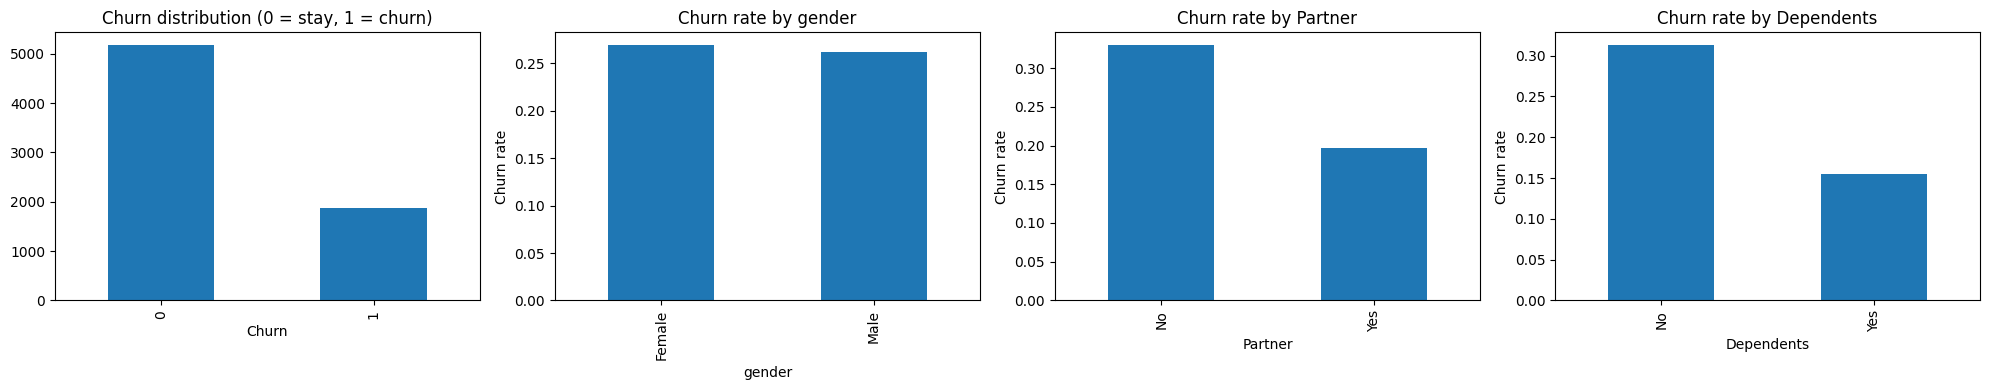

In [40]:
cats = [c for c in df.columns if not pd.api.types.is_numeric_dtype(df[c])
        and c != "Churn" and 1 < df[c].nunique() <= 6][:3]

fig, axes = plt.subplots(1, len(cats) + 1, figsize=(5 * (len(cats) + 1), 4))
target.value_counts().plot(kind="bar", ax=axes[0])
axes[0].set_title("Churn distribution (0 = stay, 1 = churn)")
for ax, c in zip(axes[1:], cats):
    target.groupby(df[c]).mean().plot(kind="bar", ax=ax)
    ax.set_title(f"Churn rate by {c}")
    ax.set_ylabel("Churn rate")
plt.tight_layout()

plt.savefig("eda_charts.png", dpi=150)
plt.show()

*Churn is lower for customers with a partner or dependents.*

In [34]:
import seaborn as sns

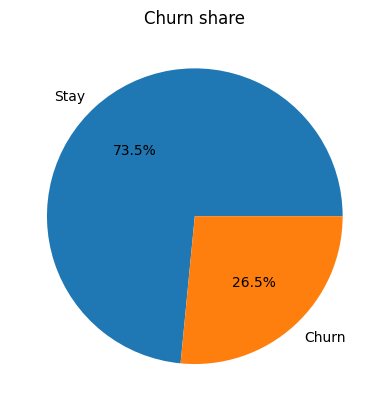

In [35]:
target.map({0: "Stay", 1: "Churn"}).value_counts().plot(kind="pie", autopct="%1.1f%%", ylabel="")
plt.title("Churn share")

plt.savefig("pie_chart.png", dpi=150)
plt.show()

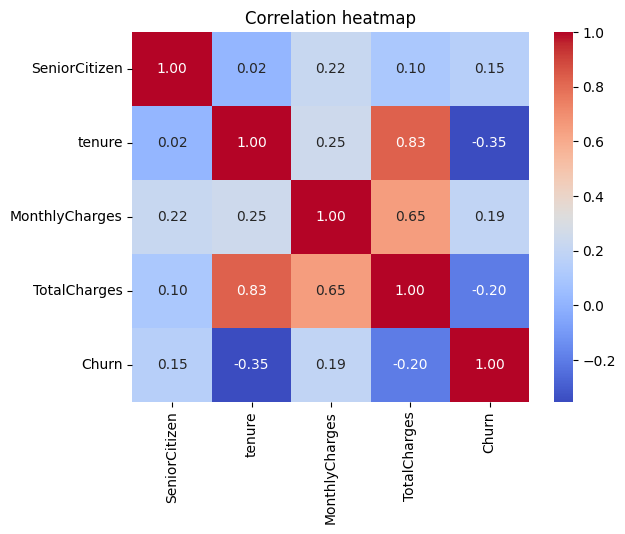

In [36]:
d = df.assign(Churn=target, TotalCharges=pd.to_numeric(df["TotalCharges"], errors="coerce")).select_dtypes("number")
sns.heatmap(d.corr(), annot=True, fmt=".2f", cmap="coolwarm")
plt.title("Correlation heatmap")

plt.savefig("correlation_heatmap.png", dpi=150)
plt.show()

*Longer tenure means less churn.*

In [31]:
%cd "/Users/sonamkumari/Churn Prediction"
%run train.py

/Users/sonamkumari/Churn Prediction


/Library/Frameworks/Python.framework/Versions/3.10/lib/python3.10/site-packages/IPython/core/magics/osm.py:417: UserWarning: This is now an optional IPython functionality, setting dhist requires you to install the `pickleshare` library.
  self.shell.db['dhist'] = compress_dhist(dhist)[-100:]


In [ ]:
import json

m = json.load(open("/Users/sonamkumari/Churn Prediction/models/metrics.json"))
table = pd.DataFrame({n: {k: v for k, v in r.items() if not isinstance(v, (list, dict))}
                      for n, r in m["models"].items()}).T
table.round(3)

,accuracy,precision,recall,f1,roc_auc,cv_roc_auc
Logistic Regression,0.740,0.506,0.777,0.613,0.840,0.846
Random Forest,0.770,0.551,0.715,0.622,0.840,0.846
Gradient Boosting,0.801,0.663,0.508,0.575,0.838,0.848
KNN,0.785,0.605,0.540,0.571,0.818,0.823


In [38]:
import pandas as pd

d = pd.read_csv("/Users/sonamkumari/Churn Prediction/data/churn.csv")

d.drop(columns=["Churn"]).sample(30, random_state=1).to_csv(
    "/Users/sonamkumari/Churn Prediction/sample_bulk.csv", index=False)

In [39]:
import json

m = json.load(open("/Users/sonamkumari/Churn Prediction/models/metrics.json"))
table = pd.DataFrame({n: {k: v for k, v in r.items() if not isinstance(v, (list, dict))}
                      for n, r in m["models"].items()}).T
table.round(3)

,accuracy,precision,recall,f1,roc_auc,cv_roc_auc
Logistic Regression,0.740,0.506,0.777,0.613,0.840,0.846
Random Forest,0.770,0.551,0.715,0.622,0.840,0.846
Gradient Boosting,0.801,0.663,0.508,0.575,0.838,0.848
KNN,0.785,0.605,0.540,0.571,0.818,0.823
1D CNN,0.744,0.511,0.723,0.599,0.829,NaN
